# Validasi Metode: Analisis Sentimen Komentar YouTube Portugal vs Kroasia dengan Transfer Learning IndoBERT

Notebook ini mereproduksi seluruh angka pada naskah (Tabel 1 sampai 6, Gambar 2 sampai 5) dari dua berkas data bersih:
`train_dataset_80.csv` dan `test_dataset_20.csv` (kolom: `comment`, `sentiment`, `sarkasme`).

**Perubahan dibanding versi sebelumnya**
1. Regex kategori penalti tidak lagi menangkap kata `penaldo` (ejekan untuk Ronaldo). Semua aturan kata kunci dipusatkan di satu sel dan dibandingkan dengan aturan lama.
2. Kode Tabel 1 (aspek entitas) ditambahkan.
3. Prediksi, probabilitas, dan daftar kesalahan prediksi disimpan ke CSV (bahan Tabel 6).
4. Perangkat (GPU/CPU) dicatat otomatis. Latensi diukur dengan pemanasan dan sinkronisasi GPU, diulang beberapa kali.
5. Uji signifikansi memakai McNemar pada prediksi berpasangan, ditambah selang kepercayaan bootstrap. Uji lama pada subset data uji dihapus.
6. Ada audit data: komentar kembar latih/uji, label sarkasme vs. penanda tawa, dan komentar yang terpotong pada batas 96 token.
7. Opsi pelatihan beberapa seed. Seed pertama (42) menjadi hasil utama di paper.
8. Semua angka untuk paper ditulis ke `hasil_validasi/ringkasan_angka_paper.json`.

Jalankan sel dari atas ke bawah. Sel bertanda **[GPU]** memakai PyTorch dan IndoBERT.

In [1]:
!pip install -q transformers torch scikit-learn statsmodels matplotlib scipy psutil

## 1. Konfigurasi dan impor

In [2]:
import os, re, json, time, random, platform, warnings, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import label_binarize
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")

# ---- Konfigurasi ----------------------------------------------------------
SEED = 42                      # seed utama (dipakai untuk angka di paper)
SEEDS = [42, 43, 44]           # seed pertama = hasil utama; sisanya untuk melaporkan variasi
MODEL_NAME = "indobenchmark/indobert-base-p1"
MAX_LEN, BATCH_SIZE, EPOCHS = 96, 32, 3
LR, WEIGHT_DECAY, WARMUP_STEPS, DROPOUT = 3e-5, 0.005, 30, 0.05
LATENCY_REPEATS = 5
BOOTSTRAP_N = 2000
NEAR_DUP_THRESHOLD = 0.85      # kemiripan karakter (TF-IDF char n-gram) untuk komentar "hampir kembar"
RUN_ROSID = True               # model deteksi sarkasme (opsional, tidak dilaporkan di paper)
OUT_DIR = "hasil_validasi"
os.makedirs(OUT_DIR, exist_ok=True)

LABELS = ["negatif", "netral", "positif"]
SENT_MAP = {"negatif": 0, "netral": 1, "positif": 2}
INV_MAP = {v: k for k, v in SENT_MAP.items()}
CLASS_NAMES = ["Negatif (0)", "Netral (1)", "Positif (2)"]

random.seed(SEED); np.random.seed(SEED)
SUMMARY = {}      # semua angka untuk paper dikumpulkan di sini
print("Konfigurasi dimuat. Output ->", os.path.abspath(OUT_DIR))

Konfigurasi dimuat. Output -> /content/hasil_validasi


## 2. Pemuatan data dan pemeriksaan integritas

In [3]:
def find_file(name):
    candidates = [name, f"dataset/{name}", f"/content/{name}", f"/content/dataset/{name}",
                  f"/content/drive/MyDrive/dataset/{name}"]
    return next((p for p in candidates if os.path.exists(p)), None)

train_file, test_file = find_file("train_dataset_80.csv"), find_file("test_dataset_20.csv")
if train_file is None or test_file is None:       # coba mount Google Drive (hanya di Colab)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        train_file, test_file = find_file("train_dataset_80.csv"), find_file("test_dataset_20.csv")
    except Exception:
        pass
if train_file is None or test_file is None:
    raise FileNotFoundError("train_dataset_80.csv / test_dataset_20.csv tidak ditemukan. "
                            "Letakkan di folder kerja, ./dataset, atau Google Drive (MyDrive/dataset).")

df_train = pd.read_csv(train_file); df_test = pd.read_csv(test_file)
for d in (df_train, df_test):
    d["comment"] = d["comment"].fillna("").astype(str)
assert set(df_train.sentiment) <= set(LABELS) and set(df_test.sentiment) <= set(LABELS)
assert set(df_train.sarkasme) <= {"ya", "tidak"} and set(df_test.sarkasme) <= {"ya", "tidak"}

y_train = df_train.sentiment.map(SENT_MAP).values
y_test = df_test.sentiment.map(SENT_MAP).values
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
df_all = pd.concat([df_train, df_test], ignore_index=True)

print(f"Data latih: {len(df_train):,} | Data uji: {len(df_test):,} | Total: {len(df_all):,}")
print("Distribusi latih:", df_train.sentiment.value_counts().to_dict())
print("Distribusi uji  :", df_test.sentiment.value_counts().to_dict())
print("Sarkasme latih  :", df_train.sarkasme.value_counts().to_dict(), "| uji:", df_test.sarkasme.value_counts().to_dict())
SUMMARY["data"] = {
    "n_train": len(df_train), "n_test": len(df_test), "n_total": len(df_all),
    "train_dist": df_train.sentiment.value_counts().to_dict(),
    "test_dist": df_test.sentiment.value_counts().to_dict(),
    "all_dist": df_all.sentiment.value_counts().to_dict(),
    "sarkasme_train_ya": int((df_train.sarkasme == "ya").sum()),
}

Mounted at /content/drive
Data latih: 2,652 | Data uji: 664 | Total: 3,316
Distribusi latih: {'negatif': 1395, 'positif': 636, 'netral': 621}
Distribusi uji  : {'negatif': 349, 'positif': 160, 'netral': 155}
Sarkasme latih  : {'tidak': 2587, 'ya': 65} | uji: {'tidak': 652, 'ya': 12}


### 2.1 Audit komentar kembar (kebocoran latih → uji)

Komentar yang persis sama tidak ada, tetapi komentar yang sama setelah huruf besar/kecil, tanda baca, dan urutan kata
dinormalisasi, atau yang sangat mirip, tetap bisa membuat evaluasi sedikit optimistis. Sel ini hanya **melaporkan**;
angka utama tidak diubah.

In [4]:
def norm_key(s):
    # normalisasi: huruf kecil, hanya huruf, kata diurutkan (mengabaikan urutan kata)
    return " ".join(sorted(re.findall(r"[a-z]+", str(s).lower())))

df_train["key"] = df_train.comment.map(norm_key); df_test["key"] = df_test.comment.map(norm_key)
exact_overlap = len(set(df_train.comment) & set(df_test.comment))
key_overlap_mask = df_test.key.isin(set(df_train.key)).values

vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(pd.concat([df_train.comment, df_test.comment]))
sim = cosine_similarity(vec_char.transform(df_test.comment), vec_char.transform(df_train.comment))
max_sim, nn_idx = sim.max(1), sim.argmax(1)
near_dup_mask = (max_sim >= NEAR_DUP_THRESHOLD) | key_overlap_mask

audit = df_test.assign(sim_terdekat=max_sim.round(3),
                       komentar_latih_terdekat=df_train.comment.values[nn_idx],
                       label_latih_terdekat=df_train.sentiment.values[nn_idx])
audit = audit[near_dup_mask].copy()
audit["label_beda"] = audit.sentiment != audit.label_latih_terdekat
audit.drop(columns=["key"]).to_csv(f"{OUT_DIR}/audit_komentar_kembar_uji_vs_latih.csv", index=False)

train_dups = df_train[df_train.key.duplicated(keep=False)].sort_values("key")
conflict_groups = int((train_dups.groupby("key").sentiment.nunique() > 1).sum()) if len(train_dups) else 0
train_dups.drop(columns=["key"]).to_csv(f"{OUT_DIR}/audit_komentar_kembar_dalam_latih.csv", index=False)

print(f"Komentar persis sama latih/uji         : {exact_overlap}")
print(f"Baris uji dg kembaran ternormalisasi   : {int(key_overlap_mask.sum())}")
print(f"Baris uji 'hampir kembar' (sim>={NEAR_DUP_THRESHOLD}) atau kembar: {int(near_dup_mask.sum())} "
      f"({near_dup_mask.mean()*100:.1f}%), di antaranya label berbeda: {int(audit.label_beda.sum())}")
print(f"Kembar dalam data latih: {len(train_dups)} baris, grup dengan label bertentangan: {conflict_groups}")
SUMMARY["audit_duplikat"] = {
    "exact_overlap": exact_overlap, "normalized_overlap_test_rows": int(key_overlap_mask.sum()),
    "near_dup_rows": int(near_dup_mask.sum()), "near_dup_pct": round(float(near_dup_mask.mean() * 100), 2),
    "near_dup_label_conflict": int(audit.label_beda.sum()), "train_dup_groups_conflict": conflict_groups,
}

Komentar persis sama latih/uji         : 0
Baris uji dg kembaran ternormalisasi   : 9
Baris uji 'hampir kembar' (sim>=0.85) atau kembar: 21 (3.2%), di antaranya label berbeda: 7
Kembar dalam data latih: 19 baris, grup dengan label bertentangan: 3


### 2.2 Audit label sarkasme

Jika label sarkasme sebagian besar mengikuti penanda tawa ("wkwk", "haha", ...), koefisien sarkasme di regresi
mengukur kosakata, bukan sarkasme. Sel ini menghitung seberapa besar tumpang tindihnya.

In [5]:
LAUGH_RE = re.compile(r"wk|kwk|haha|hehe|xixi")
for d in (df_train, df_test, df_all):
    d["tawa"] = d.comment.str.lower().str.contains(LAUGH_RE)

ct = pd.crosstab(df_train.tawa, df_train.sarkasme)
share_ya = df_train.loc[df_train.sarkasme == "ya", "tawa"].mean()
share_tidak = df_train.loc[df_train.sarkasme == "tidak", "tawa"].mean()
print("Latih: tabel silang penanda tawa x sarkasme\n", ct, sep="")
print(f"Komentar sarkasme yang mengandung penanda tawa: {share_ya*100:.1f}% | non-sarkasme: {share_tidak*100:.1f}%")

# Aturan sederhana "ada penanda tawa -> sarkasme": seberapa jauh label bisa ditebak tanpa model apa pun?
for nama, d in (("latih", df_train), ("uji", df_test)):
    y = (d.sarkasme == "ya").astype(int); p = d.tawa.astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    print(f"Aturan 'penanda tawa' pada data {nama}: precision {pr*100:.1f}% | recall {rc*100:.1f}% | F1 {f1*100:.1f}%")
    SUMMARY.setdefault("audit_sarkasme", {})[nama] = {"precision": round(pr*100,2), "recall": round(rc*100,2), "f1": round(f1*100,2)}
SUMMARY["audit_sarkasme"]["share_tawa_di_sarkasme_latih_pct"] = round(float(share_ya*100), 1)
SUMMARY["audit_sarkasme"]["share_tawa_di_nonsarkasme_latih_pct"] = round(float(share_tidak*100), 1)

Latih: tabel silang penanda tawa x sarkasme
sarkasme  tidak  ya
tawa               
False      2538  13
True         49  52
Komentar sarkasme yang mengandung penanda tawa: 80.0% | non-sarkasme: 1.9%
Aturan 'penanda tawa' pada data latih: precision 51.5% | recall 80.0% | F1 62.7%
Aturan 'penanda tawa' pada data uji: precision 42.9% | recall 100.0% | F1 60.0%


## 3. Baseline TF-IDF (Naive Bayes, Random Forest, SVM, Logistic Regression)

In [6]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train = tfidf.fit_transform(df_train.comment)         # fit hanya pada data latih
X_test = tfidf.transform(df_test.comment)

ml_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "SVM (Linear SVC)": LinearSVC(C=1.0, random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
}

def softmax_rows(z):
    e = np.exp(z - z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

def multiclass_metrics(y_true, preds, probs):
    acc = accuracy_score(y_true, preds)
    _, _, f1_macro, _ = precision_recall_fscore_support(y_true, preds, average="macro", zero_division=0)
    _, _, f1_w, _ = precision_recall_fscore_support(y_true, preds, average="weighted", zero_division=0)
    yb = label_binarize(y_true, classes=[0, 1, 2])
    return {"Akurasi (%)": round(acc*100, 2), "Macro-F1 (%)": round(f1_macro*100, 2), "Weighted-F1 (%)": round(f1_w*100, 2),
            "ROC-AUC (%)": round(roc_auc_score(yb, probs, average="macro", multi_class="ovr")*100, 2),
            "PR-AUC (%)": round(average_precision_score(yb, probs, average="macro")*100, 2)}

ml_preds, ml_probs, rows = {}, {}, {}
for name, clf in ml_models.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test) if hasattr(clf, "predict_proba") else softmax_rows(clf.decision_function(X_test))
    ml_preds[name], ml_probs[name] = preds, probs
    rows[name] = multiclass_metrics(y_test, preds, probs)
df_baseline = pd.DataFrame(rows).T
print(df_baseline[["Akurasi (%)", "Macro-F1 (%)", "ROC-AUC (%)", "PR-AUC (%)"]])
df_baseline.to_csv(f"{OUT_DIR}/baseline_tfidf_metrik.csv")
SUMMARY["baseline"] = df_baseline.to_dict(orient="index")

                         Akurasi (%)  Macro-F1 (%)  ROC-AUC (%)  PR-AUC (%)
Multinomial Naive Bayes        64.61         53.38        83.18       72.06
Random Forest                  69.73         63.16        83.77       71.45
SVM (Linear SVC)               71.54         67.80        84.58       73.76
Logistic Regression            72.89         68.10        86.13       76.21


## 4. IndoBERT + Global Average Pooling (arsitektur Shaw dkk., 2025) **[GPU]**

Pelatihan dilakukan untuk setiap seed di `SEEDS`. Seed pertama menjadi hasil utama (dipakai di Tabel 3 sampai 5 dan latensi).
Tidak ada data validasi dan tidak ada early stopping: jumlah epoch tetap 3 sesuai Shaw dkk.

In [7]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
import psutil, transformers, sklearn, statsmodels

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    DEVICE_NAME = torch.cuda.get_device_name(0)
else:
    DEVICE_NAME = f"CPU {platform.processor() or platform.machine()} | {os.cpu_count()} core | {torch.get_num_threads()} thread torch"
ENV = {"python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
       "sklearn": sklearn.__version__, "statsmodels": statsmodels.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "device": DEVICE.type, "device_name": DEVICE_NAME}
SUMMARY["lingkungan"] = ENV
print("Perangkat:", DEVICE.type.upper(), "-", DEVICE_NAME)
print({k: v for k, v in ENV.items() if k not in ("device", "device_name")})

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class IndoBERTShaw2025(nn.Module):
    def __init__(self, model_name, n_classes=3, dense1=64, dense2=16, dropout=DROPOUT):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        h = self.encoder.config.hidden_size
        self.head = nn.Sequential(
            nn.Linear(h, dense1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dense1, dense2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dense2, n_classes))

    def forward(self, input_ids, attention_mask):
        tok = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state   # (B, T, H)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (tok * mask).sum(1) / mask.sum(1).clamp(min=1e-6)                                  # Global Average Pooling
        return self.head(pooled)

class EncodedDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
        self.y = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "labels": self.y[i]}

# Berapa komentar yang terpotong pada MAX_LEN token?
def count_truncated(texts):
    lens = [len(x) for x in tokenizer(list(texts), truncation=False, add_special_tokens=True)["input_ids"]]
    return int(sum(l > MAX_LEN for l in lens)), int(max(lens))
trunc_train, maxlen_train = count_truncated(df_train.comment)
trunc_test, maxlen_test = count_truncated(df_test.comment)
print(f"Komentar terpotong (> {MAX_LEN} token): latih {trunc_train} ({trunc_train/len(df_train)*100:.1f}%), "
      f"uji {trunc_test} ({trunc_test/len(df_test)*100:.1f}%)")
SUMMARY["pemotongan_token"] = {"max_len": MAX_LEN, "latih": trunc_train, "uji": trunc_test,
                               "latih_pct": round(trunc_train/len(df_train)*100, 2), "uji_pct": round(trunc_test/len(df_test)*100, 2)}

train_ds, test_ds = EncodedDataset(df_train.comment, y_train), EncodedDataset(df_test.comment, y_test)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

@torch.no_grad()
def predict_probs(model):
    model.eval(); out = []
    for b in test_loader:
        logits = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE))
        out.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(out)

def train_one(seed):
    set_seed(seed)
    model = IndoBERTShaw2025(MODEL_NAME).to(DEVICE)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=WARMUP_STEPS,
                                                num_training_steps=len(loader) * EPOCHS)
    criterion = nn.CrossEntropyLoss(); losses = []
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); total = 0.0
        for b in loader:
            optimizer.zero_grad()
            loss = criterion(model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)), b["labels"].to(DEVICE))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step(); total += loss.item()
        losses.append(total / len(loader))
        print(f"  seed {seed} | epoch {ep+1}/{EPOCHS} | loss rata-rata {losses[-1]:.4f}")
    return model, losses, time.time() - t0

@torch.no_grad()
def measure_latency(model, repeats=LATENCY_REPEATS):
    # waktu forward pass model (termasuk pemindahan batch ke perangkat), TANPA tokenisasi dan prapemrosesan teks
    model.eval(); times = []
    for r in range(repeats + 1):                      # putaran pertama = pemanasan, tidak dihitung
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for b in test_loader:
            model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE))
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        if r > 0: times.append(time.perf_counter() - t0)
    ms = np.array(times) / len(df_test) * 1000
    return {"latency_ms_mean": float(ms.mean()), "latency_ms_sd": float(ms.std()),
            "throughput_rps_mean": float((1000 / ms).mean()), "repeats": repeats, "batch_size": BATCH_SIZE}

seed_rows, probs_by_seed, losses_by_seed = [], {}, {}
for i, seed in enumerate(SEEDS):
    print(f"== Pelatihan IndoBERT, seed {seed} ==")
    model, losses, t_train = train_one(seed)
    probs = predict_probs(model)
    probs_by_seed[seed], losses_by_seed[seed] = probs, losses
    m = multiclass_metrics(y_test, probs.argmax(1), probs); m["Seed"] = seed; m["Waktu latih (s)"] = round(t_train, 1)
    seed_rows.append(m)
    print("  ->", {k: v for k, v in m.items() if k in ("Akurasi (%)", "Macro-F1 (%)", "Weighted-F1 (%)")})
    if i == 0:                                        # hanya seed utama yang diukur latensinya
        lat = measure_latency(model)
        lat["model_size_mb_fp32"] = sum(p.numel() * p.element_size() for p in model.parameters()) / 1024 ** 2
        lat["ram_rss_mb"] = psutil.Process(os.getpid()).memory_info().rss / 1024 ** 2
        if DEVICE.type == "cuda":
            lat["gpu_peak_alloc_mb"] = torch.cuda.max_memory_allocated() / 1024 ** 2
        lat["device"], lat["device_name"] = DEVICE.type, DEVICE_NAME
        print("  Latensi:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in lat.items()})
    del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

df_seeds = pd.DataFrame(seed_rows).set_index("Seed")
df_seeds.to_csv(f"{OUT_DIR}/indobert_per_seed.csv")
print("\nRingkasan antar-seed (rata-rata ± simpangan baku):")
for col in ["Akurasi (%)", "Macro-F1 (%)", "Weighted-F1 (%)", "ROC-AUC (%)", "PR-AUC (%)"]:
    print(f"  {col:16s}: {df_seeds[col].mean():.2f} ± {df_seeds[col].std(ddof=0):.2f}")

bert_probs = probs_by_seed[SEEDS[0]]
bert_preds = bert_probs.argmax(1)
bert_losses = losses_by_seed[SEEDS[0]]
SUMMARY["latensi"] = lat
SUMMARY["indobert_seed_utama"] = {"seed": SEEDS[0], "loss_per_epoch": [round(x, 4) for x in bert_losses]}
SUMMARY["indobert_antar_seed"] = {
    c: {"mean": round(float(df_seeds[c].mean()), 2), "sd": round(float(df_seeds[c].std(ddof=0)), 2)}
    for c in ["Akurasi (%)", "Macro-F1 (%)", "Weighted-F1 (%)", "ROC-AUC (%)", "PR-AUC (%)"]} if len(SEEDS) > 1 else {}

Perangkat: CUDA - Tesla T4
{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'numpy': '2.1.3', 'pandas': '2.2.3'}


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

  seed 42 | epoch 1/3 | loss rata-rata 0.8842
  seed 42 | epoch 2/3 | loss rata-rata 0.5971
  seed 42 | epoch 3/3 | loss rata-rata 0.4513
  -> {'Akurasi (%)': 78.77, 'Macro-F1 (%)': 76.7, 'Weighted-F1 (%)': 78.67}
  Latensi: {'latency_ms_mean': 5.03, 'latency_ms_sd': 0.015, 'throughput_rps_mean': 198.806, 'repeats': 5, 'batch_size': 32, 'model_size_mb_fp32': 474.898, 'ram_rss_mb': 1817.625, 'gpu_peak_alloc_mb': 3328.475, 'device': 'cuda', 'device_name': 'Tesla T4'}
== Pelatihan IndoBERT, seed 43 ==


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  seed 43 | epoch 1/3 | loss rata-rata 0.8968
  seed 43 | epoch 2/3 | loss rata-rata 0.5749
  seed 43 | epoch 3/3 | loss rata-rata 0.4050
  -> {'Akurasi (%)': 79.52, 'Macro-F1 (%)': 76.65, 'Weighted-F1 (%)': 79.1}
== Pelatihan IndoBERT, seed 44 ==


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  seed 44 | epoch 1/3 | loss rata-rata 0.8734
  seed 44 | epoch 2/3 | loss rata-rata 0.5954
  seed 44 | epoch 3/3 | loss rata-rata 0.4352
  -> {'Akurasi (%)': 78.61, 'Macro-F1 (%)': 76.32, 'Weighted-F1 (%)': 78.37}

Ringkasan antar-seed (rata-rata ± simpangan baku):
  Akurasi (%)     : 78.97 ± 0.40
  Macro-F1 (%)    : 76.56 ± 0.17
  Weighted-F1 (%) : 78.71 ± 0.30
  ROC-AUC (%)     : 90.11 ± 0.18
  PR-AUC (%)      : 81.85 ± 0.87


## 5. Evaluasi IndoBERT (seed utama): Tabel 3, 4, 5, kesalahan prediksi (Tabel 6), dan uji signifikansi

In [8]:
# ---- Tabel 4: metrik per kelas + rata-rata makro dan terbobot ----------------
p, r, f, s = precision_recall_fscore_support(y_test, bert_preds, labels=[0, 1, 2], zero_division=0)
pm, rm, fm, _ = precision_recall_fscore_support(y_test, bert_preds, average="macro", zero_division=0)
pw, rw, fw, _ = precision_recall_fscore_support(y_test, bert_preds, average="weighted", zero_division=0)
yb = y_test_bin
roc_macro = roc_auc_score(yb, bert_probs, average="macro", multi_class="ovr")
pr_macro = average_precision_score(yb, bert_probs, average="macro")
acc = accuracy_score(y_test, bert_preds)

tabel4 = pd.DataFrame({
    "Kelas": CLASS_NAMES + ["Rata-rata Makro", "Rata-rata Terbobot"],
    "Precision (%)": list(np.round(p*100, 2)) + [round(pm*100, 2), round(pw*100, 2)],
    "Recall (%)": list(np.round(r*100, 2)) + [round(rm*100, 2), round(rw*100, 2)],
    "F1-Score (%)": list(np.round(f*100, 2)) + [round(fm*100, 2), round(fw*100, 2)],
    "Jumlah": list(s) + [int(s.sum()), int(s.sum())]})
print(tabel4.to_string(index=False))
print(f"\nAkurasi {acc*100:.2f}% | ROC-AUC {roc_macro*100:.2f}% | PR-AUC {pr_macro*100:.2f}%")
tabel4.to_csv(f"{OUT_DIR}/tabel4_metrik_per_kelas.csv", index=False)

# ---- Tabel 5: TP, TN, FP, FN One-vs-All ---------------------------------------
cm = confusion_matrix(y_test, bert_preds, labels=[0, 1, 2])
rows5 = []
for i, nm in enumerate(CLASS_NAMES):
    tp = int(cm[i, i]); fn = int(cm[i].sum() - tp); fp = int(cm[:, i].sum() - tp); tn = int(cm.sum() - tp - fn - fp)
    rows5.append({"Kelas": nm, "TP": tp, "TN": tn, "FP": fp, "FN": fn, "Total": tp + tn + fp + fn})
tabel5 = pd.DataFrame(rows5); print("\n", tabel5.to_string(index=False), sep="")
tabel5.to_csv(f"{OUT_DIR}/tabel5_tp_tn_fp_fn.csv", index=False)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{OUT_DIR}/matriks_konfusi.csv")

# ---- Tabel 3: perbandingan model --------------------------------------------
m_bert = multiclass_metrics(y_test, bert_preds, bert_probs)
tabel3 = pd.DataFrame([
    {"Model": "Multinomial Naive Bayes", "Fitur": "TF-IDF (1,2)", **df_baseline.loc["Multinomial Naive Bayes", ["Akurasi (%)", "Macro-F1 (%)"]].to_dict()},
    {"Model": "Random Forest", "Fitur": "TF-IDF (100 pohon)", **df_baseline.loc["Random Forest", ["Akurasi (%)", "Macro-F1 (%)"]].to_dict()},
    {"Model": "SVM (Linear SVC)", "Fitur": "TF-IDF (1,2)", **df_baseline.loc["SVM (Linear SVC)", ["Akurasi (%)", "Macro-F1 (%)"]].to_dict()},
    {"Model": "Logistic Regression", "Fitur": "TF-IDF (1,2)", **df_baseline.loc["Logistic Regression", ["Akurasi (%)", "Macro-F1 (%)"]].to_dict()},
    {"Model": "IndoBERT + Avg Pooling", "Fitur": "Transformer", "Akurasi (%)": m_bert["Akurasi (%)"], "Macro-F1 (%)": m_bert["Macro-F1 (%)"]}])
print("\n", tabel3.to_string(index=False), sep=""); tabel3.to_csv(f"{OUT_DIR}/tabel3_perbandingan_model.csv", index=False)
best_base = max(ml_preds, key=lambda k: accuracy_score(y_test, ml_preds[k]))
SUMMARY["indobert"] = {**m_bert, "tabel4": tabel4.to_dict(orient="records"), "tabel5": tabel5.to_dict(orient="records"),
                       "selisih_akurasi_vs_baseline_terbaik_poin": round(m_bert["Akurasi (%)"] - df_baseline.loc[best_base, "Akurasi (%)"], 2),
                       "selisih_macroF1_vs_baseline_terbaik_poin": round(m_bert["Macro-F1 (%)"] - df_baseline.loc[best_base, "Macro-F1 (%)"], 2),
                       "baseline_terbaik": best_base}

# ---- Kesalahan prediksi untuk Tabel 6 -----------------------------------------
df_pred = df_test.drop(columns=["key", "tawa"], errors="ignore").copy()
df_pred["prediksi"] = [INV_MAP[i] for i in bert_preds]
for j, c in enumerate(LABELS): df_pred[f"prob_{c}"] = bert_probs[:, j].round(4)
df_pred["keyakinan"] = bert_probs.max(1).round(4)
df_pred["mirip_data_latih"] = near_dup_mask
df_pred["benar"] = df_pred.prediksi == df_pred.sentiment
df_pred.to_csv(f"{OUT_DIR}/prediksi_indobert_data_uji.csv", index=False)
errors = df_pred[~df_pred.benar].sort_values("keyakinan", ascending=False)
errors.to_csv(f"{OUT_DIR}/kesalahan_prediksi_indobert.csv", index=False)
print(f"\nKesalahan prediksi: {len(errors)} dari {len(df_pred)} -> {OUT_DIR}/kesalahan_prediksi_indobert.csv")
print("Pilih contoh Tabel 6 dari file tersebut (kolom: comment, sentiment=label aktual, prediksi). 10 teratas menurut keyakinan:")
print(errors[["comment", "sentiment", "prediksi", "keyakinan"]].head(10).to_string(index=False, max_colwidth=70))

# ---- Selang kepercayaan bootstrap ------------------------------------------------
rng = np.random.default_rng(SEED); n = len(y_test); accs, f1s = [], []
for _ in range(BOOTSTRAP_N):
    idx = rng.integers(0, n, n)
    accs.append(accuracy_score(y_test[idx], bert_preds[idx]))
    f1s.append(f1_score(y_test[idx], bert_preds[idx], average="macro", zero_division=0))
ci = lambda a: [round(float(np.percentile(a, 2.5))*100, 2), round(float(np.percentile(a, 97.5))*100, 2)]
print(f"\nSelang kepercayaan 95% (bootstrap {BOOTSTRAP_N}x): akurasi {ci(accs)} | macro-F1 {ci(f1s)}")
SUMMARY["indobert"]["ci95_akurasi"], SUMMARY["indobert"]["ci95_macroF1"] = ci(accs), ci(f1s)

# ---- McNemar: IndoBERT vs setiap baseline (prediksi berpasangan pada 664 data uji) --------------
mcn = {}
for name, bp in ml_preds.items():
    a, b = (bert_preds == y_test), (bp == y_test)
    table = [[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]]
    res = mcnemar(table, exact=True)
    mcn[name] = {"IndoBERT_benar_baseline_salah": table[0][1], "IndoBERT_salah_baseline_benar": table[1][0], "p_value": float(res.pvalue)}
    print(f"McNemar IndoBERT vs {name:24s}: hanya-IndoBERT-benar {table[0][1]:3d} | hanya-baseline-benar {table[1][0]:3d} | p = {res.pvalue:.2e}")
SUMMARY["mcnemar"] = mcn

# ---- Sensitivitas: tanpa komentar yang mirip data latih --------------------------------------
keep = ~near_dup_mask
acc_clean = accuracy_score(y_test[keep], bert_preds[keep])
f1_clean = f1_score(y_test[keep], bert_preds[keep], average="macro", zero_division=0)
print(f"\nTanpa {int(near_dup_mask.sum())} komentar mirip data latih (n={int(keep.sum())}): akurasi {acc_clean*100:.2f}% | macro-F1 {f1_clean*100:.2f}%")
SUMMARY["indobert"]["tanpa_kembar"] = {"n": int(keep.sum()), "akurasi": round(acc_clean*100, 2), "macroF1": round(f1_clean*100, 2)}

# ---- Perbandingan dengan validasi silang baseline pada data latih ----------------------
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED); cv = {}
texts = df_train.comment.values
for name, mk in {"SVM (Linear SVC)": lambda: LinearSVC(C=1.0, random_state=SEED),
                 "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
                 "Multinomial Naive Bayes": lambda: MultinomialNB()}.items():
    sc = []
    for tr, va in skf.split(texts, y_train):
        v = TfidfVectorizer(ngram_range=(1, 2), max_features=5000); Xtr = v.fit_transform(texts[tr]); Xva = v.transform(texts[va])
        pr_ = mk().fit(Xtr, y_train[tr]).predict(Xva)
        sc.append(f1_score(y_train[va], pr_, average="macro", zero_division=0) * 100)
    cv[name] = {"cv_macroF1_mean": round(float(np.mean(sc)), 2), "cv_macroF1_sd": round(float(np.std(sc)), 2),
                "test_macroF1": float(df_baseline.loc[name, "Macro-F1 (%)"])}
    print(f"CV 5-lipat (data latih) {name:24s}: macro-F1 {np.mean(sc):.2f} ± {np.std(sc):.2f} | pada data uji: {df_baseline.loc[name, 'Macro-F1 (%)']:.2f}")
SUMMARY["cv_baseline"] = cv

             Kelas  Precision (%)  Recall (%)  F1-Score (%)  Jumlah
       Negatif (0)          82.58       84.24         83.40     349
        Netral (1)          71.03       66.45         68.67     155
       Positif (2)          77.30       78.75         78.02     160
   Rata-rata Makro          76.97       76.48         76.70     664
Rata-rata Terbobot          78.61       78.77         78.67     664

Akurasi 78.77% | ROC-AUC 89.90% | PR-AUC 80.65%

      Kelas  TP  TN  FP  FN  Total
Negatif (0) 294 253  62  55    664
 Netral (1) 103 467  42  52    664
Positif (2) 126 467  37  34    664

                  Model              Fitur  Akurasi (%)  Macro-F1 (%)
Multinomial Naive Bayes       TF-IDF (1,2)        64.61         53.38
          Random Forest TF-IDF (100 pohon)        69.73         63.16
       SVM (Linear SVC)       TF-IDF (1,2)        71.54         67.80
    Logistic Regression       TF-IDF (1,2)        72.89         68.10
 IndoBERT + Avg Pooling        Transformer        7

## 6. Aturan kata kunci terpusat: kategori insiden VAR (Tabel 2) dan aspek entitas (Tabel 1)

> **Catatan metodologis.** Kategori VAR dan aspek ditentukan dari **kata kunci** pada teks komentar, bukan dari sentimen
> terhadap aspek tersebut, dan kategori VAR saling eksklusif menurut urutan prioritas (offside → penalti → gol dianulir → wasit/VAR/FIFA).
> Karena kata seperti "curang" dan "wasit" sendiri bermuatan negatif, odds ratio yang dihasilkan adalah **asosiasi leksikal**, bukan efek sebab-akibat.
> Tulis begitu di paper.

In [9]:
# ---------- Aturan BARU --------------------------------------------------------------
# VAR: kata "var" berdiri sendiri, plus plesetan umum yang memang merujuk ke VAR
VAR_RE = r"\bvar(?:nya|tugal|drid|r)?\b"
OFFSIDE_RE = r"\b(?:off?\s?side|ofsaid|offsaid|opset|opside|offsid|offiside)\w*"
# Penalti: penalti/pinalti/penalty/pinalty. TIDAK mencocokkan "penaldo"/"pinaldo" (ejekan untuk Ronaldo)
PENALTY_RE = r"\bp[ei]nalt[iy]\w*"
OVERTURN_RE = r"\b(?:di)?anulir\w*|\bdibatal\w*|\bbatalin\b|\bbatal\b"
REFEREE_RE = rf"\b(?:wasit|curang|fifa)\w*|{VAR_RE}"

def code_var_incident(text):
    t = str(text).lower()
    if re.search(OFFSIDE_RE, t): return "1_Offside_VAR"
    if re.search(PENALTY_RE, t): return "2_Penalty_Check"
    if re.search(OVERTURN_RE, t): return "3_Goal_Overturned"
    if re.search(REFEREE_RE, t): return "4_Referee_Protocol"
    return "0_Non_VAR"

# ---------- Aturan LAMA (untuk perbandingan) ------------------------------------------
def code_var_incident_legacy(text):
    t = str(text).lower()
    if re.search(r"\b(offside|ofsaid|opset|offsid)\w*", t): return "1_Offside_VAR"
    if re.search(r"\b(penalti|pinalti|penaldo)\w*", t): return "2_Penalty_Check"
    if re.search(r"\b(anulir|dianulir|batal)\w*", t): return "3_Goal_Overturned"
    if re.search(r"\b(wasit|var|curang|fifa)\w*", t): return "4_Referee_Protocol"
    return "0_Non_VAR"

df_all["VARCall_Type"] = df_all.comment.map(code_var_incident)
df_all["VARCall_Legacy"] = df_all.comment.map(code_var_incident_legacy)
cmp = pd.concat([df_all.VARCall_Legacy.value_counts().rename("Aturan lama"),
                 df_all.VARCall_Type.value_counts().rename("Aturan baru")], axis=1).fillna(0).astype(int).sort_index()
print("Jumlah komentar per kategori VAR, aturan lama vs baru:\n", cmp, sep="")
penaldo_only = df_all.comment.str.lower().str.contains(r"\bp[ei]naldo\w*") & ~df_all.comment.str.lower().str.contains(PENALTY_RE)
print(f"\nKomentar yang hanya menyebut 'penaldo' (bukan penalti): {int(penaldo_only.sum())}")
cmp.to_csv(f"{OUT_DIR}/perbandingan_aturan_var_lama_baru.csv")

# ---------- Aspek entitas (Tabel 1) ----------------------------------------------------
ASPECT_WASIT_RE = rf"{OFFSIDE_RE}|{PENALTY_RE}|{OVERTURN_RE}|{REFEREE_RE}|\bhakim\w*"
ASPECT_CROATIA_RE = r"\b(?:modric|modrik|luka|luca|kroasia|croatia|croasia|kroatia|perisic|kovacic|gvardiol|sucic|pasalic)\w*"
ASPECT_PORTUGAL_RE = r"\b(?:ronaldo|cr7|cr|dodo|penaldo|portugal|potugal|portu|leao|ramos|bruno|vitinha|nuno)\w*"

def assign_aspect(text):
    t = str(text).lower()
    if re.search(ASPECT_WASIT_RE, t): return "Wasit & VAR"
    if re.search(ASPECT_CROATIA_RE, t): return "Modric & Kroasia"
    if re.search(ASPECT_PORTUGAL_RE, t): return "Ronaldo & Portugal"
    return "Lainnya / Konteks Umum"

def aspect_table(d):
    d = d.assign(Aspek=d.comment.map(assign_aspect))
    ct = pd.crosstab(d.Aspek, d.sentiment).reindex(columns=LABELS, fill_value=0)
    ct["Total"] = ct.sum(axis=1)
    order = ["Ronaldo & Portugal", "Wasit & VAR", "Modric & Kroasia", "Lainnya / Konteks Umum"]
    ct = ct.reindex(order).fillna(0).astype(int)
    total = pd.DataFrame(ct.sum()).T; total.index = ["Total"]
    ct = pd.concat([ct, total])
    out = pd.DataFrame(index=ct.index)
    for c in LABELS:
        out[f"{c.capitalize()} (n, %)"] = [f"{ct.loc[i, c]} ({ct.loc[i, c]/ct.loc[i, 'Total']*100:.2f}%)" for i in ct.index]
    out["Total"] = ct["Total"]
    return out, ct

tabel1_test, ct1_test = aspect_table(df_test)
tabel1_all, ct1_all = aspect_table(df_all)
print("\nTABEL 1 (data uji, n=664):\n", tabel1_test.to_string(), sep="")
print("\nVersi seluruh data (n=3.316):\n", tabel1_all.to_string(), sep="")
tabel1_test.to_csv(f"{OUT_DIR}/tabel1_aspek_data_uji.csv"); tabel1_all.to_csv(f"{OUT_DIR}/tabel1_aspek_seluruh_data.csv")
SUMMARY["tabel1_uji"] = ct1_test.to_dict(orient="index"); SUMMARY["tabel1_semua"] = ct1_all.to_dict(orient="index")

Jumlah komentar per kategori VAR, aturan lama vs baru:
                    Aturan lama  Aturan baru
0_Non_VAR                  1997         1976
1_Offside_VAR               424          488
2_Penalty_Check             267          212
3_Goal_Overturned           140          138
4_Referee_Protocol          488          502

Komentar yang hanya menyebut 'penaldo' (bukan penalti): 93

TABEL 1 (data uji, n=664):
                       Negatif (n, %) Netral (n, %) Positif (n, %)  Total
Ronaldo & Portugal        78 (45.09%)   52 (30.06%)    43 (24.86%)    173
Wasit & VAR              177 (66.79%)   59 (22.26%)    29 (10.94%)    265
Modric & Kroasia          50 (34.72%)   27 (18.75%)    67 (46.53%)    144
Lainnya / Konteks Umum    44 (53.66%)   17 (20.73%)    21 (25.61%)     82
Total                    349 (52.56%)  155 (23.34%)   160 (24.10%)    664

Versi seluruh data (n=3.316):
                       Negatif (n, %) Netral (n, %) Positif (n, %)  Total
Ronaldo & Portugal       387 (47.08%) 

## 7. Regresi: OLS (Smith dkk.) dan Logit insiden VAR (Walker dkk.): Tabel 2

In [10]:
df_all["Sentiment_Score"] = df_all.sentiment.map({"negatif": -1.0, "netral": 0.0, "positif": 1.0})
df_all["VAR_Controversy"] = df_all.comment.str.lower().str.contains(
    rf"{VAR_RE}|\bwasit\w*|\b(?:di)?anulir\w*|{OFFSIDE_RE}|{PENALTY_RE}|\bcurang\w*|\bhakim\w*", regex=True).astype(int)
df_all["Sarcasm_Dummy"] = (df_all.sarkasme == "ya").astype(int)
df_all["Comment_Length"] = df_all.comment.str.split().str.len()

def assign_entity_group(text):             # kelompok tim/pemain untuk fixed effects (tidak sama dengan aspek Tabel 1)
    t = str(text).lower()
    if re.search(r"\b(modric|kroasia|croatia|perisic|kovacic|gvardiol)\w*", t): return "Croatia_Modric"
    if re.search(r"\b(ronaldo|cr7|dodo|portugal|leao|ramos|bruno)\w*", t): return "Portugal_Ronaldo"
    return "General_Match"
df_all["Entity_Group"] = df_all.comment.map(assign_entity_group)

ols_pooled = smf.ols("Sentiment_Score ~ VAR_Controversy + Sarcasm_Dummy + Comment_Length", data=df_all).fit(cov_type="HC1")
ols_fe = smf.ols("Sentiment_Score ~ VAR_Controversy + Sarcasm_Dummy + Comment_Length + C(Entity_Group)", data=df_all).fit(cov_type="HC1")
print("=== OLS pooled (HC1) ===\n", ols_pooled.summary().tables[1], sep="")
print("\n=== OLS fixed effects kelompok entitas (HC1) ===")
for v in ["VAR_Controversy", "Sarcasm_Dummy", "Comment_Length"]:
    print(f"  {v:16s}: koef {ols_fe.params[v]:+.4f} | p = {ols_fe.pvalues[v]:.3e}")
print(f"  R-kuadrat FE: {ols_fe.rsquared:.4f}")
SUMMARY["ols_fe"] = {v: {"koef": round(float(ols_fe.params[v]), 4), "p": float(ols_fe.pvalues[v])} for v in ["VAR_Controversy", "Sarcasm_Dummy", "Comment_Length"]}
SUMMARY["ols_fe"]["r2"] = round(float(ols_fe.rsquared), 4)

# ---- Logit: kategori VAR eksklusif (Tabel 2) --------------------------------------------------
df_all["Negative_Reaction"] = (df_all.sentiment == "negatif").astype(int)
for col, cat in {"Call_Offside": "1_Offside_VAR", "Call_Penalty": "2_Penalty_Check",
                 "Call_Overturn": "3_Goal_Overturned", "Call_Referee": "4_Referee_Protocol"}.items():
    df_all[col] = (df_all.VARCall_Type == cat).astype(int)
logit = smf.logit("Negative_Reaction ~ Call_Offside + Call_Penalty + Call_Overturn + Call_Referee + Sarcasm_Dummy", data=df_all).fit(disp=0)
ci_ = logit.conf_int()
def fmt_p(p): return "< 0,0001" if p < 1e-4 else f"{p:.4f}".replace(".", ",")

labels2 = {"Call_Offside": "1_Offside_VAR", "Call_Penalty": "2_Penalty_Check", "Call_Overturn": "3_Goal_Overturned",
           "Call_Referee": "4_Referee_Protocol"}
g = df_all.groupby("VARCall_Type").Negative_Reaction.agg(["count", "mean"])
rows2 = [{"Kategori": "0_Non_VAR", "Jumlah": int(g.loc["0_Non_VAR", "count"]), "Negatif (%)": round(g.loc["0_Non_VAR", "mean"]*100, 2),
          "Koef. Logit": round(float(logit.params["Intercept"]), 4), "Odds Ratio": 1.0, "CI95 OR": "baseline", "p-value": ""}]
for col, cat in labels2.items():
    rows2.append({"Kategori": cat, "Jumlah": int(g.loc[cat, "count"]), "Negatif (%)": round(g.loc[cat, "mean"]*100, 2),
                  "Koef. Logit": round(float(logit.params[col]), 4), "Odds Ratio": round(float(np.exp(logit.params[col])), 3),
                  "CI95 OR": f"{np.exp(ci_.loc[col, 0]):.2f} - {np.exp(ci_.loc[col, 1]):.2f}", "p-value": fmt_p(logit.pvalues[col])})
tabel2 = pd.DataFrame(rows2)
print("\nTABEL 2 (seluruh 3.316 komentar):\n", tabel2.to_string(index=False), sep="")
print(f"Sarcasm_Dummy: OR {np.exp(logit.params['Sarcasm_Dummy']):.3f} | p = {logit.pvalues['Sarcasm_Dummy']:.2e}")
tabel2.to_csv(f"{OUT_DIR}/tabel2_kategori_var_logit.csv", index=False)
SUMMARY["tabel2"] = tabel2.to_dict(orient="records")
SUMMARY["logit_sarkasme_OR"] = round(float(np.exp(logit.params["Sarcasm_Dummy"])), 3)

# ---- Sensitivitas: kategori tidak eksklusif (satu komentar boleh masuk beberapa kategori) -----------------
df_all["has_offside"] = df_all.comment.str.lower().str.contains(OFFSIDE_RE).astype(int)
df_all["has_penalty"] = df_all.comment.str.lower().str.contains(PENALTY_RE).astype(int)
df_all["has_overturn"] = df_all.comment.str.lower().str.contains(OVERTURN_RE).astype(int)
df_all["has_referee"] = df_all.comment.str.lower().str.contains(REFEREE_RE).astype(int)
logit_multi = smf.logit("Negative_Reaction ~ has_offside + has_penalty + has_overturn + has_referee + Sarcasm_Dummy", data=df_all).fit(disp=0)
print("\nSensitivitas, kategori tidak eksklusif (odds ratio):")
for v in ["has_offside", "has_penalty", "has_overturn", "has_referee", "Sarcasm_Dummy"]:
    print(f"  {v:14s}: OR {np.exp(logit_multi.params[v]):.3f} | p = {logit_multi.pvalues[v]:.2e}")
SUMMARY["logit_tidak_eksklusif_OR"] = {v: round(float(np.exp(logit_multi.params[v])), 3) for v in ["has_offside", "has_penalty", "has_overturn", "has_referee", "Sarcasm_Dummy"]}

=== OLS pooled (HC1) ===
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.2012      0.023     -8.787      0.000      -0.246      -0.156
VAR_Controversy    -0.3780      0.028    -13.439      0.000      -0.433      -0.323
Sarcasm_Dummy      -0.3684      0.083     -4.428      0.000      -0.532      -0.205
Comment_Length      0.0050      0.001      3.729      0.000       0.002       0.008

=== OLS fixed effects kelompok entitas (HC1) ===
  VAR_Controversy : koef -0.3464 | p = 2.190e-33
  Sarcasm_Dummy   : koef -0.3350 | p = 7.350e-05
  Comment_Length  : koef +0.0034 | p = 1.130e-02
  R-kuadrat FE: 0.0714

TABEL 2 (seluruh 3.316 komentar):
          Kategori  Jumlah  Negatif (%)  Koef. Logit  Odds Ratio     CI95 OR  p-value
         0_Non_VAR    1976        44.74      -0.2304       1.000    baseline         
     1_Offside_VAR     488        73.16     

## 8. Gambar untuk paper (Gambar 2 sampai 5) dan penyimpanan angka

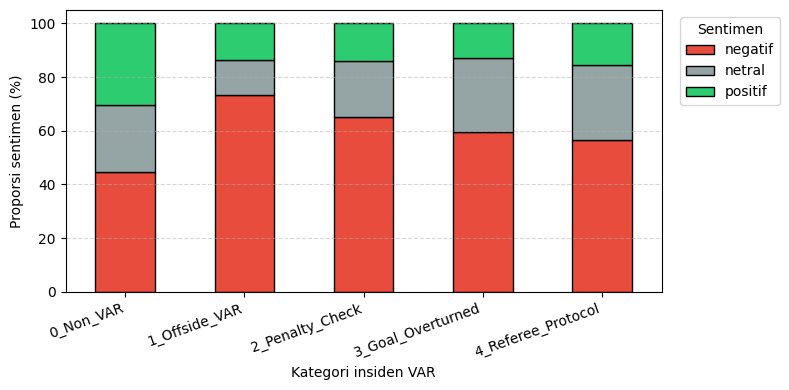

In [11]:
def save_fig(name):
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

# Gambar 2: proporsi sentimen per kategori VAR (seluruh data)
ct2 = pd.crosstab(df_all.VARCall_Type, df_all.sentiment, normalize="index")[LABELS] * 100
ct2.plot(kind="bar", stacked=True, color=["#e74c3c", "#95a5a6", "#2ecc71"], edgecolor="black", figsize=(8, 4))
plt.xlabel("Kategori insiden VAR"); plt.ylabel("Proporsi sentimen (%)"); plt.xticks(rotation=20, ha="right")
plt.legend(title="Sentimen", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.grid(axis="y", linestyle="--", alpha=.5)
save_fig("gambar2_proporsi_sentimen_per_kategori_var")

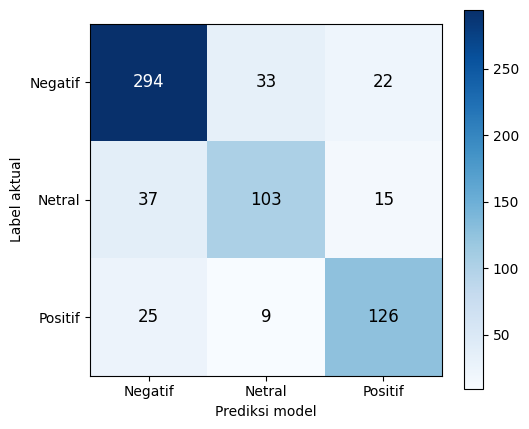

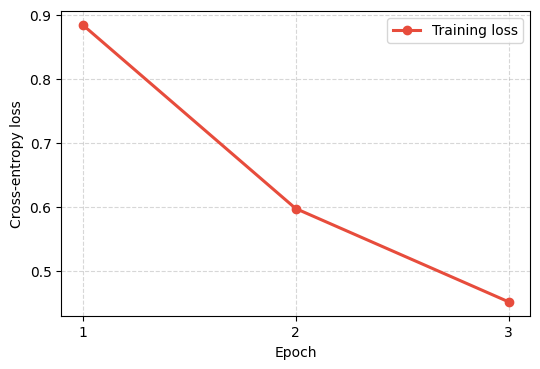

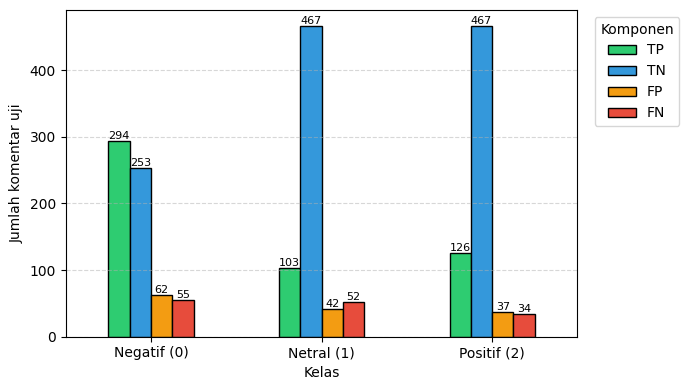

In [12]:
# Gambar 3: matriks konfusi
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(["Negatif", "Netral", "Positif"]); ax.set_yticklabels(["Negatif", "Netral", "Positif"])
ax.set_xlabel("Prediksi model"); ax.set_ylabel("Label aktual")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=12)
fig.colorbar(im, ax=ax); save_fig("gambar3_matriks_konfusi")

# Gambar 4: kurva training loss (seed utama)
plt.figure(figsize=(5.5, 3.8))
plt.plot(range(1, EPOCHS + 1), bert_losses, marker="o", linewidth=2.2, color="#e74c3c", label="Training loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.xticks(range(1, EPOCHS + 1)); plt.grid(True, linestyle="--", alpha=.5); plt.legend()
save_fig("gambar4_kurva_training_loss")

# Gambar 5: TP, TN, FP, FN per kelas
comp = tabel5.set_index("Kelas")[["TP", "TN", "FP", "FN"]]
ax = comp.plot(kind="bar", figsize=(7, 4), edgecolor="black", color=["#2ecc71", "#3498db", "#f39c12", "#e74c3c"])
for c in ax.containers: ax.bar_label(c, fontsize=8)
plt.ylabel("Jumlah komentar uji"); plt.xticks(rotation=0); plt.legend(title="Komponen", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=.5); save_fig("gambar5_tp_tn_fp_fn")

## 9. (Opsional) Model deteksi sarkasme Rosid dkk. **[GPU]**

In [13]:
if RUN_ROSID:
    import torch.nn.functional as F
    y_tr_s = (df_train.sarkasme == "ya").astype(int).values; y_te_s = (df_test.sarkasme == "ya").astype(int).values
    tok = lambda t: re.findall(r"[a-z']+", str(t).lower())
    tr_toks, te_toks = df_train.comment.map(tok).tolist(), df_test.comment.map(tok).tolist()
    cnt = Counter(w for ts in tr_toks for w in ts)
    VOCAB = {"<pad>": 0, "<unk>": 1}
    for w, c in cnt.most_common(30000):
        if c >= 2: VOCAB[w] = len(VOCAB)
    MAXLEN_S = 40
    enc = lambda ts: ([VOCAB.get(w, 1) for w in ts][:MAXLEN_S] + [0] * MAXLEN_S)[:MAXLEN_S]
    Xs_tr = torch.tensor([enc(t) for t in tr_toks]); Xs_te = torch.tensor([enc(t) for t in te_toks])

    class MHACovBi(nn.Module):
        def __init__(self, vocab_size, emb_dim=600, filters=128, heads=4, kernel=5, gru=128, drop=0.5):
            super().__init__()
            self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
            self.conv = nn.Conv1d(emb_dim, filters, kernel, padding=kernel // 2); self.bn = nn.BatchNorm1d(filters)
            self.attn = nn.MultiheadAttention(filters, heads, dropout=drop, batch_first=True)
            self.gru = nn.GRU(filters, gru, batch_first=True, bidirectional=True); self.drop = nn.Dropout(drop); self.fc = nn.Linear(gru * 2, 1)
        def forward(self, x):
            c = F.relu(self.bn(self.conv(self.emb(x).transpose(1, 2)))).transpose(1, 2)
            a, _ = self.attn(c, c, c); g, _ = self.gru(a + c)
            return self.fc(self.drop(g.mean(1))).squeeze(-1)

    set_seed(SEED)
    mha = MHACovBi(len(VOCAB)).to(DEVICE)
    opt = torch.optim.Adam(mha.parameters(), lr=1e-3, weight_decay=1e-4)
    posw = torch.tensor([(len(y_tr_s) - y_tr_s.sum()) / max(y_tr_s.sum(), 1)], dtype=torch.float32).to(DEVICE)
    lossf = nn.BCEWithLogitsLoss(pos_weight=posw)
    dl = DataLoader(list(zip(Xs_tr, torch.tensor(y_tr_s, dtype=torch.float32))), batch_size=64, shuffle=True)
    for ep in range(12):
        mha.train()
        for xb, yb in dl:
            opt.zero_grad(); lossf(mha(xb.to(DEVICE)), yb.to(DEVICE)).backward(); opt.step()
    mha.eval()
    with torch.no_grad(): ps = torch.sigmoid(mha(Xs_te.to(DEVICE))).cpu().numpy()
    pr_s = (ps >= 0.5).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_te_s, pr_s).ravel()
    pr, rc, f1b, _ = precision_recall_fscore_support(y_te_s, pr_s, average="binary", zero_division=0)
    print(f"MHA-CovBi sarkasme (uji, hanya {int(y_te_s.sum())} sampel positif): TP {tp_} TN {tn_} FP {fp_} FN {fn_} | F1 {f1b*100:.2f}%")
    print("Catatan: sampel positif sangat sedikit dan label mengikuti penanda tawa (lihat 2.2); jangan ditafsirkan sebagai kemampuan mendeteksi sarkasme.")
    SUMMARY["rosid"] = {"TP": int(tp_), "TN": int(tn_), "FP": int(fp_), "FN": int(fn_), "F1_binary": round(f1b*100, 2)}

MHA-CovBi sarkasme (uji, hanya 12 sampel positif): TP 12 TN 651 FP 1 FN 0 | F1 96.00%
Catatan: sampel positif sangat sedikit dan label mengikuti penanda tawa (lihat 2.2); jangan ditafsirkan sebagai kemampuan mendeteksi sarkasme.


## 10. Simpan ringkasan angka untuk paper

In [14]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o

with open(f"{OUT_DIR}/ringkasan_angka_paper.json", "w", encoding="utf-8") as fh:
    json.dump(_clean(SUMMARY), fh, ensure_ascii=False, indent=2)
print("Tersimpan:", sorted(os.listdir(OUT_DIR)))
shutil.make_archive("hasil_validasi", "zip", OUT_DIR)
print("Arsip: hasil_validasi.zip")
try:
    from google.colab import files; files.download("hasil_validasi.zip")
except Exception:
    pass

Tersimpan: ['audit_komentar_kembar_dalam_latih.csv', 'audit_komentar_kembar_uji_vs_latih.csv', 'baseline_tfidf_metrik.csv', 'gambar2_proporsi_sentimen_per_kategori_var.png', 'gambar3_matriks_konfusi.png', 'gambar4_kurva_training_loss.png', 'gambar5_tp_tn_fp_fn.png', 'indobert_per_seed.csv', 'kesalahan_prediksi_indobert.csv', 'matriks_konfusi.csv', 'perbandingan_aturan_var_lama_baru.csv', 'prediksi_indobert_data_uji.csv', 'ringkasan_angka_paper.json', 'tabel1_aspek_data_uji.csv', 'tabel1_aspek_seluruh_data.csv', 'tabel2_kategori_var_logit.csv', 'tabel3_perbandingan_model.csv', 'tabel4_metrik_per_kelas.csv', 'tabel5_tp_tn_fp_fn.csv']
Arsip: hasil_validasi.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Catatan untuk revisi paper (cocokkan setelah notebook dijalankan)

| Bagian paper | Ambil dari |
|---|---|
| Tabel 1 (aspek entitas) | `tabel1_aspek_data_uji.csv` |
| Tabel 2, Abstrak, Hasil 3.1, Kesimpulan (OR, % negatif) | `tabel2_kategori_var_logit.csv`, `ringkasan_angka_paper.json` → `tabel2` |
| Koefisien OLS (VAR, sarkasme) di Hasil 3.1 | `ringkasan_angka_paper.json` → `ols_fe` |
| Tabel 3, 4, 5 | `tabel3_*.csv`, `tabel4_*.csv`, `tabel5_*.csv` |
| Tabel 6 (analisis kesalahan) | `kesalahan_prediksi_indobert.csv` (kolom `sentiment` = label aktual, `prediksi` = hasil model) |
| Perangkat dan latensi | `ringkasan_angka_paper.json` → `latensi` (tulis GPU/CPU sesuai `device_name`) |
| Klaim "tanpa duplikasi" | `audit_komentar_kembar_uji_vs_latih.csv` dan `ringkasan_angka_paper.json` → `audit_duplikat` |
| Keterbatasan (sarkasme, seed, token terpotong) | `audit_sarkasme`, `indobert_antar_seed`, `pemotongan_token` |

Karena aturan kata kunci diperbaiki, **angka Tabel 1, Tabel 2, dan koefisien OLS dapat berbeda dari versi sebelumnya**;
semua teks yang menyebut angka tersebut (Abstrak, 3.1, Kesimpulan) harus diperbarui.